#### ▶  Autograd(자동미분)
: PyTorch에서 연산과정을 추적하고 역전파를 통해 미분값을 자동으로 계산하는 기능
- **미분 계산 자동화**
- **기울기 계산** : 각 입력값과 모델의 가중치가 손실함수에 미치는 영향 계산
- **모델 학습 지원** : 계산한 기울기를 Optimizer에 전달하여 가중치 업데이트

In [1]:
import torch

#### ▶ Autograd의 기본 흐름
1. 미분할 텐서에 requires_grad = True 설정
2. 해당 텐서를 사용하여 연산 수행
3. 결과 텐서에 backward() 실행.
4. 원본 텐서의 grad속성에서 미분값 확인(생략가능)
  * 실수 형태만 미분 가능
#### 1. requires_grad
- True : 해당 텐서에 대한 연산을 추적하여 기울기를 계산할 수 있도록 설정
- False : 기본값. 해당 텐서에 대한 연산을 추적하지 않음
- 일반적으로 모델이 학습해야 하는 가중치(weight)와 편향(bias)에 True를 설정함

In [2]:
x = torch.tensor(1.0, requires_grad = True)
print(x)

tensor(1., requires_grad=True)


In [3]:
# 1.
x = torch.tensor([1.0], requires_grad = True)

# 2. 함수 계산
y = x**2
print(y)

# 3. 역전파 실행
y.backward()

# 4. 결과와 기울기 확인
print('y :',y)
print('x의 기울기 :', x.grad)


tensor([1.], grad_fn=<PowBackward0>)
y : tensor([1.], grad_fn=<PowBackward0>)
x의 기울기 : tensor([2.])


In [4]:
x = torch.tensor(1.0, requires_grad=True)
x.requires_grad=False
    # requires_grad=False 추적 종료
    # transger leanrning 할 때 사용
    # 내가 만들어 놓은 학습된 모델에서 일부분만 학습시키고 싶을 때 나머지 부분만 
y = x**2
print(y)
# y.backward()        # 추적할 수 없어서 오류

tensor(1.)


In [5]:
x = torch.tensor([2.0, 4.0], requires_grad = True)
y = x * 3

print('x.requires_grad : ', x.requires_grad)
print('y.requires_grad : ', y.requires_grad)
print('x.is_leaf :', x.is_leaf)
print('y.is_leaf :', y.is_leaf)
print('y.grad_fn :', y.grad_fn)

x.requires_grad :  True
y.requires_grad :  True
x.is_leaf : True
y.is_leaf : False
y.grad_fn : <MulBackward0 object at 0x0000025FEB1C9FF0>


#### 2. 연쇄법칙(Chain Rule)
함수가 여러 연산으로 연결되어 있으면 각 연산의 미분값을 연쇄적으로 곱하여 최종 기울기를 계산함<br>
        # 밑에서 위로 계산

In [6]:
x = torch.tensor([1.0], requires_grad=True)
y = x**2
print(y)

z = 3 * y
print(z)

z.backward()
print(x.grad)
print(y.grad)       # y는 Non-leaf Tensor이기 때문에 미분값 출력 안됨

tensor([1.], grad_fn=<PowBackward0>)
tensor([3.], grad_fn=<MulBackward0>)
tensor([6.])
None


C:\Users\mega\AppData\Local\Temp\ipykernel_6036\2011199059.py:10: UserWarning: The .grad attribute of a Tensor that is not a leaf Tensor is being accessed. Its .grad attribute won't be populated during autograd.backward(). If you indeed want the .grad field to be populated for a non-leaf Tensor, use .retain_grad() on the non-leaf Tensor. If you access the non-leaf Tensor by mistake, make sure you access the leaf Tensor instead. See github.com/pytorch/pytorch/pull/30531 for more information. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\build\aten\src\ATen/core/TensorBody.h:493.)
  print(y.grad)       # y는 Non-leaf Tensor이기 때문에 미분값 출력 안됨


In [7]:
# 중간에 있는 y의 미분값 알고 싶다면
x = torch.tensor([1.0], requires_grad=True)
y = x**2
y.retain_grad()     # retain_grad() = 원래 자동으로 기울기를 저장하지 않는 Non-leaf Tensor의 기울기도 확인할 수 있게 해주는 기능

z = 3*y
z.backward()
print('x의 미분값 : ',x.grad)
print('y의 미분값 : ',y.grad)

x의 미분값 :  tensor([6.])
y의 미분값 :  tensor([3.])


In [8]:
x = torch.tensor([1.0], requires_grad=True)
y = x**2
z = 3*y

y.backward()        # y부터 미분 시작(z는 안함)
print(x.grad)


tensor([2.])


In [9]:
x = torch.tensor([1.0], requires_grad=True)
a = x**2
b = a+1
print(b)

c = b**2
c.backward()
print(x.grad)

tensor([2.], grad_fn=<AddBackward0>)
tensor([8.])


In [10]:
x = torch.tensor([1.0], requires_grad=True)
y = torch.tensor([1.0], requires_grad=True)

z = 2*x**2 + y**2
print(z)

z.backward()
print(x.grad)
print(y.grad)

tensor([3.], grad_fn=<AddBackward0>)
tensor([4.])
tensor([2.])


In [11]:
x = torch.tensor([2.0], requires_grad=True)
y = torch.tensor([3.0], requires_grad=True)

f = x**2 + 2*x*y+y**2
f.backward()

print(x.grad)
print(y.grad)

tensor([10.])
tensor([10.])


#### 6. torch.autograd.grad()
: 지정한 입력텐서에 대한 기울기(미분값)를 반환하는 함수

- backward() : 계산한 기울기를 입력텐서의 .grad에 누적
- torch.autograd.grad() : 기울기를 반환해줌 .grad에 누적하지 않음

- 사용
    1. 특정 변수의 미분값만 필요할 때
    2. 기울기를 .grad에 저장하고 싶지 않을 때
    3. 여러변수를 편미분을 동시에 구할 때 : 여러 입력 변수의 기울기를 튜플로 반환받을 수 있다

- 사용 형식
torch.autograd.grad(outputs, inputs)

In [14]:
x = torch.tensor(4., requires_grad=True)
y = x**3

gradient = torch.autograd.grad(y,x)

print('y :', y)
print('반환된 기울기 : ', gradient)
print('x.grad :',x.grad)

y : tensor(64., grad_fn=<PowBackward0>)
반환된 기울기 :  (tensor(48.),)
x.grad : None


#### 7. detach()
requires_grad = True인 텐서에 연산을 적용하면 PyToch는 연산과정을 추적함<br>
그런데 특정 텐셔부터는 더이상 gradient를 계산하지 않도록 하고 싶을 때 detach()를 사용
** 기존텐서와 값은 공유하지만, 자동 미분 계산 그래프에서 분리된 텐서를 반환**

- 원본 텐서의 연산 추적은 그대로 유지됨
- 분리된 텐서는 해당 연산 그래프를 통한 기울기 계산에 연결되지 않음
- 학습결과를 출력하거나 NumPy로 변환할 때 자주 사용함

In [15]:
x = torch.tensor([1.,2,3], requires_grad=True)
y = x*2
y_detach=y.detach()

print('y :', y)
print('y.requites_grad :', y.requires_grad)
print('y_detach :', y_detach)
print('y_detach.requires_grad :', y_detach.requires_grad)
print('y_detach.grad_fn :', y_detach.grad_fn)

y : tensor([2., 4., 6.], grad_fn=<MulBackward0>)
y.requites_grad : True
y_detach : tensor([2., 4., 6.])
y_detach.requires_grad : False
y_detach.grad_fn : None


In [16]:
# 변수의 값을 그냥 상수로 사용하고 싶을 때
x = torch.tensor(1., requires_grad=True)
y = x**2
z = y.detach()      # y값을 상수로 넣음
z = y
w = y+z     # y값이 x**2가아닌 상수 1로 들어감 -> x**2 +1
w.backward()
print(x.grad)

tensor(4.)


#### 8. torch.no_grad()
: 지정한 블록 코드 안에서는 자동 미분을 위한 연산 추적을 비활성화함

- 학습 중 모델의 가중치를 업데이트할 때
- 검증 및 예측처럼 기울기 계싼이 필요하지 않을 때
- 불필요한 계싼 그래프 생성을 줄여 메모리 사용량을 줄일 수 있음

[사용형식]
```python
with torch.no_grad() : 
    # 기울기를 추적하지 않는 연산
```

- `detach()`는 특정 텐서를 계산 그래프에서 분리하고, `no_grad`는 특정 코드 블록의 연산 추적을 막는다는 차이가 있음


In [17]:
x = torch.tensor(3., requires_grad=True)
y1= x**2

with torch.no_grad():       # 추적 안함
    y2 = x**2
    z = 2*y2

print('일반 연산 requires_grad :', y1.requires_grad)
print('no_grad 내부 연산 y2의 frquires_grad :', y2.requires_grad)
print('no_grad 내부 연산 z의 frquires_grad :', z.requires_grad)

print('y2.grad_fn :', y2.grad_fn)

일반 연산 requires_grad : True
no_grad 내부 연산 y2의 frquires_grad : False
no_grad 내부 연산 z의 frquires_grad : False
y2.grad_fn : None


- torch.no_grad()
    - 특정 코드 블록에 적용
    - 블록 내부의 연산 그래프 추적을 중단
    - 블록이 끝나면 기존 상태로 복귀
- requires_grad = False
    - 특정 텐서에 적용
    - 해당 텐서에 기울기 추적을 비활성화
    - 다시 True로 변경하기 전까지 비활성화 유지

In [18]:
x = torch.tensor(1., requires_grad=True)

with torch.no_grad():
    y = x**2
    print(x.requires_grad)
    print(y)
print(x.requires_grad)

y = x**2
print(y)
print(y.requires_grad)
print('_'*30)



x = torch.tensor(1., requires_grad=True)
x.requires_grad=False
y = x**2
print(x.requires_grad)
print(y)

True
tensor(1.)
True
tensor(1., grad_fn=<PowBackward0>)
True
______________________________
False
tensor(1.)


In [19]:
%pip install torchviz

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.0.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [20]:
%pip install graphviz

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.0.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [21]:
from torchviz import make_dot

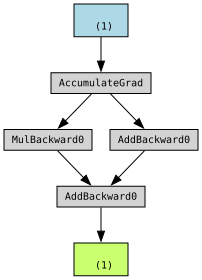

In [26]:
x = torch.tensor([1.], requires_grad = True)
make_dot(x)
make_dot(x**2+1)
make_dot((x**2+1)**2)

y = 2*x
z = 3+x
r = y+z
make_dot(r)